<a href="https://colab.research.google.com/github/Sohail-WD/defect-inspector/blob/feature%2Fgmm/GMM_Defect_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%cd /content

!git clone https://github.com/Sohail-WD/defect-inspector.git

/content
Cloning into 'defect-inspector'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 45 (delta 12), reused 25 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (45/45), 3.24 MiB | 23.04 MiB/s, done.
Resolving deltas: 100% (12/12), done.


In [ ]:
%cd /content/defect-inspector

!git status

/content/defect-inspector
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
!git checkout main
!git pull origin main
!git checkout -b feature/gmm-demo

Already on 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/Sohail-WD/defect-inspector
 * branch            main       -> FETCH_HEAD
Already up to date.
Switched to a new branch 'feature/gmm-demo'


In [ ]:
!git branch

* feature/gmm-demo
  main


In [ ]:
!ls
!ls detectors
!sed -n '1,240p' detectors/padim.py
!sed -n '1,220p' data.py

data.py  detectors  evaluate.py  README.md  results
diffusion_healing.ipynb  padim.py  vae.ipynb
"""Detector 1: MLE (PaDiM) — a Gaussian per image patch, fitted on good bottles only.

1. A pretrained ResNet18 turns each 256x256 image into a 64x64 grid of feature vectors
   (layers 1-3, stacked; 100 of the 448 dimensions kept at random to save memory).
2. For each of the 64x64 positions, fit a Gaussian to the good bottles' vectors by MLE:
   mean = average, covariance = spread (+ a little on the diagonal so it can be inverted).
3. For a test image, each position's score is its Mahalanobis distance from that
   position's Gaussian: far from "normal" = likely defect. Upscale to 256x256 and smooth.

Run from the repo root (first run downloads the ResNet18 weights, about 45 MB):
    python -m detectors.padim
"""
import numpy as np
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from torchvision.models import ResNet18_Weights, resnet18

D = 100         

In [ ]:
from pathlib import Path

dataset_path = Path("data/bottle")

print("Dataset folder exists:", dataset_path.exists())
print("Training folder exists:", (dataset_path / "train/good").exists())
print("Training images:", len(list((dataset_path / "train/good").glob("*.png"))) if (dataset_path / "train/good").exists() else 0)
print("Test folder exists:", (dataset_path / "test").exists())

Dataset folder exists: False
Training folder exists: False
Training images: 0
Test folder exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_dataset = Path("/content/drive/MyDrive/defect-inspector-data/data/bottle")

print("Drive dataset exists:", drive_dataset.exists())
if drive_dataset.exists():
    print("Training images:", len(list((drive_dataset / "train/good").glob("*.png"))))
    print("Test folders:", [p.name for p in (drive_dataset / "test").iterdir() if p.is_dir()])

Drive dataset exists: True
Training images: 209
Test folders: ['good', 'contamination', 'broken_small', 'broken_large']


In [ ]:
from pathlib import Path
import shutil

source = Path("/content/drive/MyDrive/defect-inspector-data/data/bottle")
destination = Path("/content/defect-inspector/data/bottle")

if destination.exists():
    print("Destination already exists. Not overwriting.")
else:
    shutil.copytree(source, destination)
    print("Dataset copied successfully.")

print("Training images:", len(list((destination / "train/good").glob("*.png"))))

Dataset copied successfully.
Training images: 209


In [ ]:
from data import load_mvtec

d = load_mvtec()

print("Train shape:", d["train_images"].shape)
print("Test shape:", d["test_images"].shape)
print("Labels:", d["test_labels"].shape)
print("Defect types:", sorted(set(d["test_types"])))

Train shape: (209, 256, 256, 3)
Test shape: (83, 256, 256, 3)
Labels: (83,)
Defect types: ['broken_large', 'broken_small', 'contamination', 'good']


In [ ]:
import torch
import torchvision
import sklearn
import scipy

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import torch
from detectors.padim import PaDiM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

padim = PaDiM().fit(d["train_images"])

print("PaDiM training completed!")
print("Mean shape:", padim.mu.shape)
print("Covariance inverse shape:", padim.cov_inv.shape)

Using: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 101MB/s]


PaDiM training completed!
Mean shape: torch.Size([100, 4096])
Covariance inverse shape: torch.Size([4096, 100, 100])


In [ ]:
import numpy as np
import torch

defect = d["test_labels"] == 1

imgs = d["test_images"][defect]
types = np.array(d["test_types"])[defect]

print("Defective images:", len(imgs))
print("Defect categories:", {
    t: int(np.sum(types == t)) for t in np.unique(types)
})

# Extract PaDiM heatmaps and features
maps = padim.heatmaps(imgs)
feats = padim.features(imgs)

# Establish threshold from normal test images
good_images = d["test_images"][~defect]
good_maps = padim.heatmaps(good_images)

good_max = np.quantile(good_maps, 0.99)

print("Heatmaps shape:", maps.shape)
print("Features shape:", feats.shape)
print("Good-image 99th percentile threshold:", good_max)

Defective images: 63
Defect categories: {np.str_('broken_large'): 20, np.str_('broken_small'): 22, np.str_('contamination'): 21}
Heatmaps shape: (63, 256, 256)
Features shape: torch.Size([63, 100, 64, 64])
Good-image 99th percentile threshold: 8.515979


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

X = []

for f, h in zip(feats, maps):

    # Reduce 256x256 heatmap to 64x64
    small = h.reshape(64, 4, 64, 4).mean((1, 3))

    # Select the top 1% anomalous regions
    region = torch.from_numpy(
        small >= np.quantile(small, 0.99)
    )

    # Calculate anomaly size features
    size = [
        np.log1p((h > good_max).sum()),
        h.max()
    ]

    # Combine PaDiM features and anomaly size
    feature_vector = np.concatenate([
        f[:, region].mean(1).numpy(),
        size
    ])

    X.append(feature_vector)

X = np.array(X)

print("GMM input shape:", X.shape)
print("Feature vector length:", X.shape[1])

GMM input shape: (63, 102)
Feature vector length: 102


In [ ]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce dimensions
pca = PCA(n_components=10, random_state=0)
X_pca = pca.fit_transform(X_scaled)

# Fit Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=3,
    n_init=10,
    reg_covar=1e-3,
    random_state=0
)

labels = gmm.fit_predict(X_pca)

# Evaluate clustering against actual defect types
ari = adjusted_rand_score(types, labels)

print("PCA shape:", X_pca.shape)
print("GMM clusters:", np.unique(labels))
print("ARI:", ari)
print("Explained variance by 10 components:", pca.explained_variance_ratio_.sum())

PCA shape: (63, 10)
GMM clusters: [0 1 2]
ARI: 0.3874719730941704
Explained variance by 10 components: 0.6091260480297525


In [ ]:
# Remove the final two size features
X_plain = X[:, :-2]

# Standardize
X_plain_scaled = StandardScaler().fit_transform(X_plain)

# PCA
pca_plain = PCA(n_components=10, random_state=0)
X_plain_pca = pca_plain.fit_transform(X_plain_scaled)

# GMM
gmm_plain = GaussianMixture(
    n_components=3,
    n_init=10,
    reg_covar=1e-3,
    random_state=0
)

labels_plain = gmm_plain.fit_predict(X_plain_pca)

# ARI
ari_plain = adjusted_rand_score(types, labels_plain)

print("ARI with size features:", round(ari, 4))
print("ARI without size features:", round(ari_plain, 4))
print("Improvement:", round(ari - ari_plain, 4))

ARI with size features: 0.3875
ARI without size features: 0.2822
Improvement: 0.1052


In [ ]:
import json
from pathlib import Path

Path("results").mkdir(exist_ok=True)

gmm_results = {
    "ari": float(ari),
    "ari_plain": float(ari_plain)
}

with open("results/gmm.json", "w") as f:
    json.dump(gmm_results, f, indent=2)

print(json.dumps(gmm_results, indent=2))
print("Saved:", Path("results/gmm.json").exists())

{
  "ari": 0.3874719730941704,
  "ari_plain": 0.28224389741931216
}
Saved: True


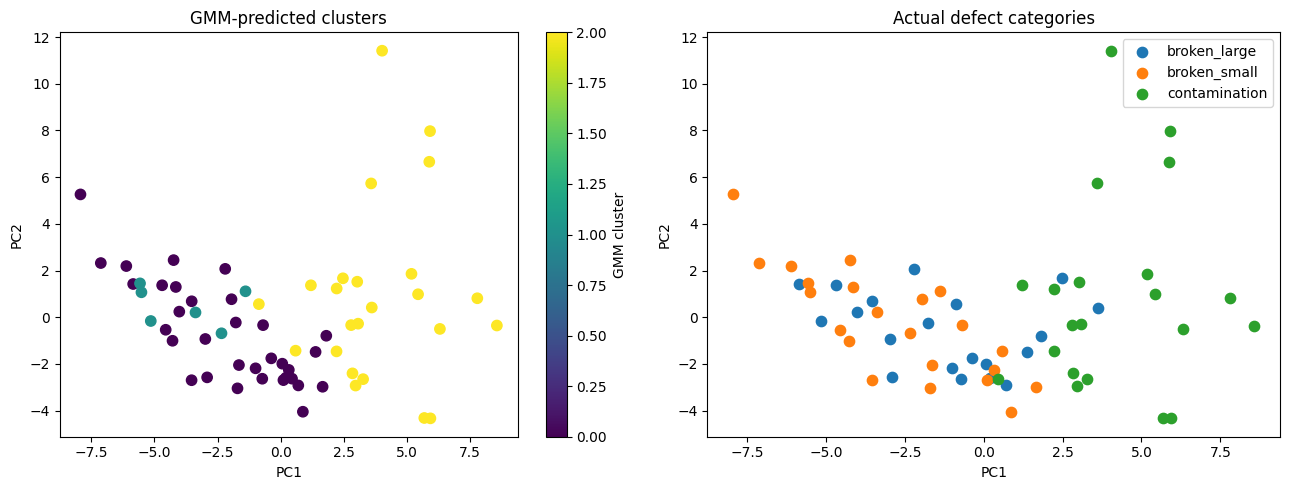

Figure saved: True


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path

# 2D PCA projection for visualization
pca_2d = PCA(n_components=2, random_state=0)
X_2d = pca_2d.fit_transform(
    StandardScaler().fit_transform(X)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Predicted GMM clusters
scatter1 = axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=labels, cmap="viridis", s=55
)
axes[0].set_title("GMM-predicted clusters")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
fig.colorbar(scatter1, ax=axes[0], label="GMM cluster")

# Actual defect categories
categories = sorted(np.unique(types))

for category in categories:
    mask = types == category
    axes[1].scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=category,
        s=55
    )

axes[1].set_title("Actual defect categories")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()

Path("results").mkdir(exist_ok=True)
plt.savefig("results/fig_gmm.png", dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved:", Path("results/fig_gmm.png").exists())

In [ ]:
from pathlib import Path

print("VAE model exists:", Path("/content/vae.pt").exists())
print("PaDiM results exist:", Path("results/padim.json").exists())
print("GMM results exist:", Path("results/gmm.json").exists())
print("GMM figure exists:", Path("results/fig_gmm.png").exists())

VAE model exists: False
PaDiM results exist: True
GMM results exist: True
GMM figure exists: True
